# Island 1 Coulomb diamonds

This notebook runs the island model from `Island1_functions.ipynb` and builds up the Coulomb diamonds one step at a time.

Later on, a defect charge switching near the island will shift the diamonds a little, and that shift is the charge noise. To see a shift we first need a clean defect-free picture that we understand.

In [1]:
# pull in the classes and functions (Island1_functions.ipynb has to be in the same folder)
%run Island1_functions.ipynb
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
%matplotlib inline
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25, 'font.size': 10})

# same colours everywhere, light blue = even n, dark blue = odd n
EVEN_C, ODD_C = '#9ecae1', '#3182bd'

## 1. The island and its numbers

$E_C$, $\alpha_g$ and $c = C_S/C_\Sigma$ are put in from the thesis, and $c = 0.5$ is an assumed symmetric island. The rest of the parameters are:

$$C_\Sigma = \frac{e^2}{E_C}, \qquad C_g = \alpha_g C_\Sigma, \qquad C_S = c\,C_\Sigma, \qquad C_D = C_\Sigma - C_S - C_g .$$

Island.centred(n_ref=6) puts the $n = 6$ diamond at $V_G = 0$.

$n$ is not the real number of electrons on the island. The code only keeps the 16 levels near the Fermi energy, and $n$ counts the electrons added to them from an arbitrary starting point. The electrons below that never change, so they just get absorbed into the background charge $q_0$. Choosing 6 is just arbitrary.

In [2]:
# build the island, n=6 diamond sits at V_G = 0
isl = Island.centred(n_ref=6)

print(f"E_C = {isl.p.E_C/meV:.2f} meV,  alpha_g = {isl.p.alpha_g:.2f},  c = {isl.p.c_S:.2f},  dE = {isl.p.dE/meV:.2f} meV,  g = {isl.p.g}")
print(f"C_sigma = {isl.C_sigma/aF:.2f} aF,  C_g = {isl.C_g/aF:.2f} aF,  C_S = {isl.C_S/aF:.2f} aF,  C_D = {isl.C_D/aF:.2f} aF")

E_C = 11.20 meV,  alpha_g = 0.08,  c = 0.50,  dE = 1.14 meV,  g = 2
C_sigma = 14.31 aF,  C_g = 1.14 aF,  C_S = 7.15 aF,  C_D = 6.01 aF


## 2. The ladder of levels

On top of the charging energy the electrons sit in single-particle levels $\Delta E = 1.14$ meV apart, two per level (spin up and down). Levels are numbered from 0 at the bottom. They fill from the bottom, so 6 electrons fill levels 0 to 2 and the 7th has to start level 3.

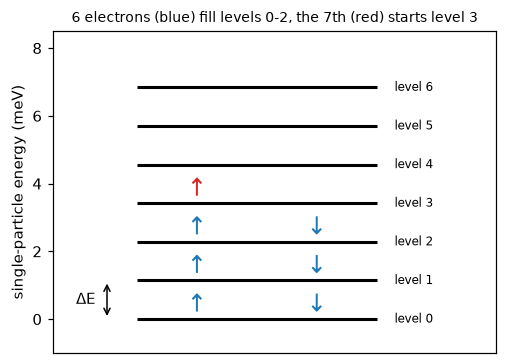

In [3]:
n_fill = 6                                   # how many electrons to draw
fig, ax = plt.subplots(figsize=(5.2, 3.8))
for k in range(7):
    e = isl.eps[k]/meV                       # energy of level k in meV
    ax.hlines(e, 0.5, 2.5, color='k', lw=2)
    ax.text(2.65, e, f'level {k}', va='center', fontsize=8)
    for s, x in enumerate((1.0, 2.0)):       # two slots per level, spin up then spin down
        idx = 2*k + s                        # which electron (counting from 0) lives in this slot
        if idx < n_fill:   ax.text(x, e+0.05, '↑' if s == 0 else '↓', ha='center', va='bottom', fontsize=16, color='C0')
        elif idx == n_fill: ax.text(x, e+0.05, '↑', ha='center', va='bottom', fontsize=16, color='C3')   # the next one in, red
# arrow showing the spacing between level 0 and 1
ax.annotate('', xy=(0.25, isl.eps[1]/meV), xytext=(0.25, isl.eps[0]/meV), arrowprops=dict(arrowstyle='<->'))
ax.text(0.15, 0.5*(isl.eps[0]+isl.eps[1])/meV, 'ΔE', ha='right', va='center')
ax.set_xlim(-0.2, 3.5); ax.set_ylim(-1, 8.5); ax.set_xticks([]); ax.grid(False)
ax.set_ylabel('single-particle energy (meV)')
ax.set_title('6 electrons (blue) fill levels 0-2, the 7th (red) starts level 3', fontsize=9)
plt.show()

## 3. Energy of $N$ electrons against gate voltage

With $N$ electrons the energy is the filled ladder plus the charging energy,

$$E(N) = \sum_p n_p\epsilon_p + \frac{(N-Q)^2}{2C_\Sigma}, \qquad Q = q_0 + C_S V_S + C_D V_D + C_g V_G .$$

Each $N$ gives a parabola in $V_G$ and the island sits on the lowest one. Where two parabolas cross, adding an electron costs no energy. That crossing is the Coulomb peak, and with zero bias it's the only place current can flow.

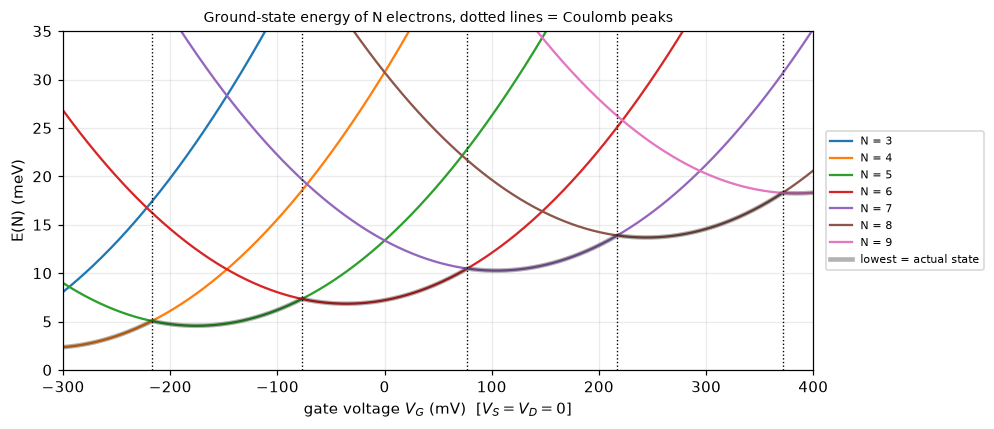

In [4]:
VGe = np.linspace(-300, 400, 800)*mV
Qe = isl.Q(0, 0, VGe)                                                # induced charge along the gate sweep, no bias
curves = {N: isl.E_ground(N, Qe)/meV for N in range(3, 10)}        # E(N) for a handful of N, in meV

fig, ax = plt.subplots(figsize=(8.8, 4))
for N, E in curves.items(): ax.plot(VGe/mV, E, label=f'N = {N}')
# thick grey line = lowest parabola at each V_G = what the island actually does
ax.plot(VGe/mV, np.min(list(curves.values()), axis=0), 'k', lw=3, alpha=.3, label='lowest = actual state')
for n in range(3, 10): ax.axvline(isl.V_peak(n)/mV, color='k', ls=':', lw=.9)   # dotted = Coulomb peaks
ax.set_xlim(-300, 400); ax.set_ylim(0, 35)
ax.set_xlabel('gate voltage $V_G$ (mV)  [$V_S = V_D = 0$]'); ax.set_ylabel('E(N) (meV)')
ax.set_title('Ground-state energy of N electrons, dotted lines = Coulomb peaks', fontsize=9)
ax.legend(fontsize=7, loc='center left', bbox_to_anchor=(1.01, .5)); plt.show()

## 4. Adding one electron

The cost of adding one more electron to an island holding $n$ is $\mu_{\rm add}(n) = E(n+1) - E(n)$. It drops linearly as $V_G$ goes up, and with source and drain at zero it hits zero at the Coulomb peaks.

The gap between neighbouring peaks is set by the addition energy $E_{\rm add}(n) = \mu_{\rm add}(n) - \mu_{\rm add}(n-1)$. It is $E_C$ when the new electron joins a spin partner in the same level, and $E_C + \Delta E$ when it has to start a new level. The peak spacing is $E_{\rm add}/(\alpha_g e)$, so it alternates between 140 and 154 mV.

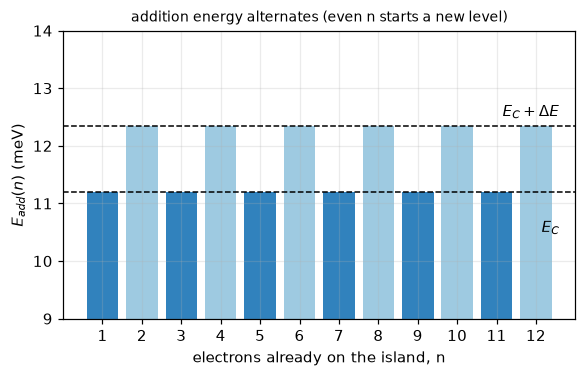

In [5]:
ns = np.arange(1, 13)
Eadd = np.array([isl.E_add(n)/meV for n in ns])

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(ns, Eadd, color=[EVEN_C if n % 2 == 0 else ODD_C for n in ns])
ax.axhline(isl.p.E_C/meV, color='k', ls='--', lw=1); ax.axhline((isl.p.E_C+isl.p.dE)/meV, color='k', ls='--', lw=1)
ax.text(12.6, isl.p.E_C/meV-0.5, '$E_C$', ha='right', va='top')
ax.text(12.6, (isl.p.E_C+isl.p.dE)/meV+0.1, '$E_C+\\Delta E$', ha='right', va='bottom')
ax.set_ylim(9, 14); ax.set_xticks(ns)
ax.set_xlabel('electrons already on the island, n'); ax.set_ylabel(r'$E_{add}(n)$ (meV)')
ax.set_title('addition energy alternates (even n starts a new level)', fontsize=9)
plt.show()

## 5. One diamond

Now put a bias $V_S$ on the source with $V_D = 0$. The source level moves to $\mu_S = -V_S$ (electrons are negative), the drain stays at $\mu_D = 0$, and the island levels shift too because $V_S$ changes $Q$. The island stays stuck at $n$ electrons (Coulomb blockade, no current) as long as

- the next electron can't get in: $\mu_{\rm add}(n) > \max(\mu_S, \mu_D)$
- the last electron can't get out: $\mu_{\rm add}(n-1) < \min(\mu_S, \mu_D)$

Plotting where this holds in $(V_G, V_S)$ gives a diamond, and the plot below comes straight from that rule.

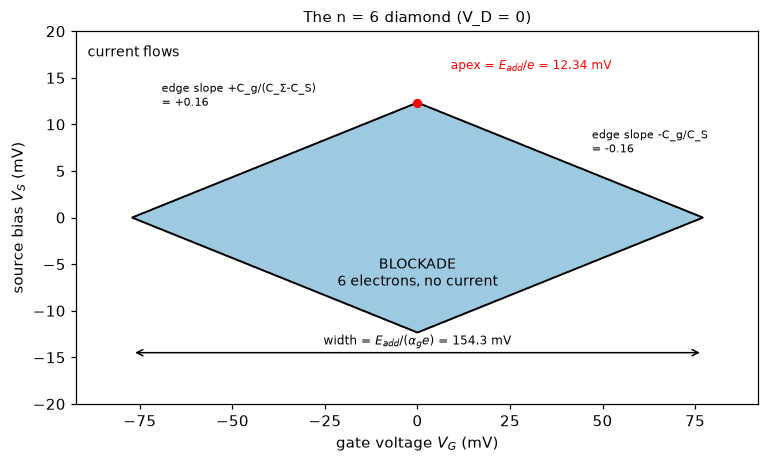

In [6]:
n0 = 6
vL, vR = isl.V_peak(n0-1)/mV, isl.V_peak(n0)/mV          # the two coulomb peaks either side of diamond n0 (mV)
VGd = np.linspace(vL-15, vR+15, 1500)*mV                 # fine grid around this one diamond
VSd = np.arange(-20, 20.001, 0.05)*mV
_, nmap = blockade_map(isl, VGd, VSd)                    # run the model, nmap says which n is stuck at each point

c = isl.C_S/isl.C_sigma
xa = vL + (1-c)*(vR-vL)                                  # top corner sits a fraction 1-c across
apex = isl.E_add(n0)/mV                                  # half height, E_add/e

fig, ax = plt.subplots(figsize=(8, 4.4))
inside = (nmap == n0).astype(float)                      # 1 inside diamond n0, 0 outside
ax.contourf(VGd/mV, VSd/mV, inside, levels=[0.5, 1.5], colors=[EVEN_C])
ax.contour(VGd/mV, VSd/mV, inside, levels=[0.5], colors='k', linewidths=1.2)
ax.plot(xa, apex, 'ro', ms=5); ax.text(xa+9, apex+3.5, f'apex = $E_{{add}}/e$ = {apex:.2f} mV', fontsize=8, color='r')
ax.annotate('', xy=(vL, -14.5), xytext=(vR, -14.5), arrowprops=dict(arrowstyle='<->'))     # width arrow
ax.text(0.5*(vL+vR), -13.7, f'width = $E_{{add}}/(\\alpha_g e)$ = {vR-vL:.1f} mV', ha='center', fontsize=8)
ax.text(vL+8, 12.0, f'edge slope +C_g/(C_Σ-C_S)\n= +{isl.C_g/(isl.C_sigma-isl.C_S):.2f}', fontsize=7.5)
ax.text(vR-30, 7.0, f'edge slope -C_g/C_S\n= {-isl.C_g/isl.C_S:.2f}', fontsize=7.5)
ax.text(0.5*(vL+vR), -6, f'BLOCKADE\n{n0} electrons, no current', ha='center', va='center', fontsize=9)
ax.text(vL-12, 17.3, 'current flows', fontsize=9)
ax.set_xlim(vL-15, vR+15); ax.set_ylim(-20, 20); ax.grid(False)
ax.set_xlabel('gate voltage $V_G$ (mV)'); ax.set_ylabel('source bias $V_S$ (mV)')
ax.set_title(f'The n = {n0} diamond (V_D = 0)', fontsize=10); plt.show()

## 6. The full diamond map

Same thing over the whole sweep. At each point of a grid in $(V_G, V_S)$, 1 mV by 0.1 mV steps, the model checks the blockade rule. White means current flows, light blue is blockade with even $n$ and dark blue is blockade with odd $n$, and the numbers are $n$.

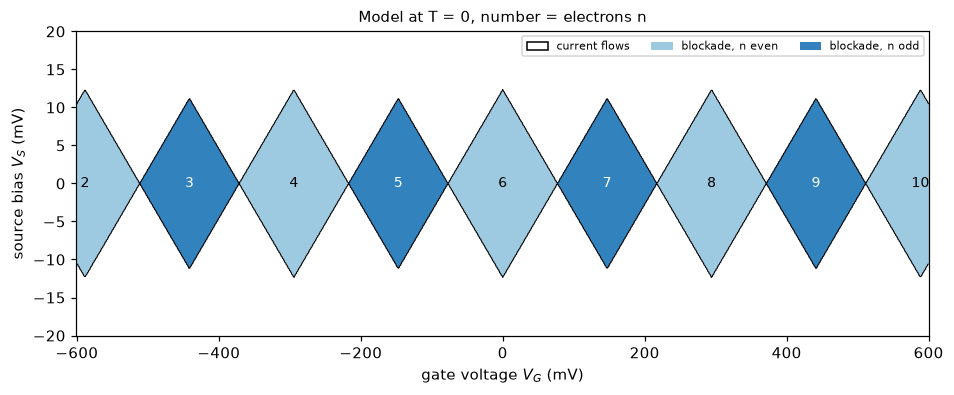

In [7]:
VG = np.arange(-600, 600.01, 1.0)*mV                    # same ranges as the thesis sweeps
VS = np.arange(-20, 20.01, 0.1)*mV
blockaded, n_map = blockade_map(isl, VG, VS)           # True where blockaded, n_map says which n

img = np.where(blockaded, 1 + (n_map % 2), 0)          # 0 = current flows, 1 = n even, 2 = n odd
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.imshow(img, extent=[-600.5, 600.5, -20.05, 20.05], origin='lower', aspect='auto',
          cmap=ListedColormap(['white', EVEN_C, ODD_C]), vmin=0, vmax=2, interpolation='nearest')
ax.contour(VG/mV, VS/mV, blockaded.astype(float), levels=[0.5], colors='k', linewidths=.7)   # edges of the blockade
for n in range(1, 2*isl.p.K - 2):                      # write n in the middle of each diamond
    xc = 0.5*(isl.V_peak(n-1)+isl.V_peak(n))/mV
    if -600 < xc < 600: ax.text(xc, 0, str(n), ha='center', va='center', fontsize=9, color='k' if n % 2 == 0 else 'w')
ax.legend(handles=[Patch(fc='white', ec='k', label='current flows'), Patch(fc=EVEN_C, label='blockade, n even'), Patch(fc=ODD_C, label='blockade, n odd')],
          loc='upper right', fontsize=7, ncol=3)
ax.set_xlabel('gate voltage $V_G$ (mV)'); ax.set_ylabel('source bias $V_S$ (mV)'); ax.grid(False)
ax.set_title('Model at T = 0, number = electrons n', fontsize=10)
plt.show()

How this compares with thesis Fig. 8.4:

- The diamond shape is the same, with corners touching at $V_S = 0$.
- Apex height: the thesis has roughly 8 to 13 mV (10.6 to 13.1 mV for the central ones) and the model gives 11.2 and 12.3 mV.
- The thesis also has lines parallel to the diamond edges (excited states and finite temperature) and diagonal lines inside the blockade. The model has none of these (yet).

## What the model can't do yet

- It's at T = 0, so there is no thermal or tunnel broadening and everything is perfectly sharp.
- It only knows blockade or no blockade, not how much current flows.
- It uses ground states only, so no excited-state lines.
- The ladder is uniform and the capacitances are constant (Beenakker's assumptions), so real diamonds with irregular widths aren't reproduced.
- The source and drain are assumed symmetric ($c = 0.5$).
- There are no defects modelled yet.

# 29/10/26

# Diamonds at finite temperature

We need to add more levels as the electron can occupy levels above and below the ones in use. So we use n=48 and use 20 levels on either side which is more than the +-20mV bias can every reach.

T is the electron temperature, the fridge was at 7mK but we estimate 100mK as a guess.

In [8]:
# an island with 48 levels, centred so that the levels in use have plenty of levels both above and below:
# electrons can then enter higher levels and leave from lower ones (the T = 0 island keeps 16 levels from n = 0)

isl_T = Island.centred(Params(K=48), n_ref=48)
n_shift = 48 - 6  # subtract from n so the diamond labels match the T = 0 plots

T_e = 100 * mK  # electron temperature (not measured; the fridge was at 7 mK)
VG = np.arange(-600, 600.01, 1.0) * mV  # same ranges as the thesis sweeps
VS = np.arange(-20, 20.01, 0.1) * mV

I_T, n_T = current_map(isl_T, VG, VS, kT=T_e)  # current and mean electron number
blockaded_T = np.abs(I_T) < 1e-6 * np.abs(I_T).max()  # "no current" = blockaded
blockaded_0, n_map_0 = blockade_map(isl_T, VG, VS)  # the T = 0 answer for the same island
print(f"points where {T_e / mK:.0f} mK and T = 0 agree on blockade: {100 * np.mean(blockaded_T == blockaded_0):.2f} %")

points where 100 mK and T = 0 agree on blockade: 99.02 %


## The current

Inside the diamonds current = 0 (Coulomb blockade) and outside it steps up every time another level or charge state becomes reachable and these steps run parallel to the diamond edges.

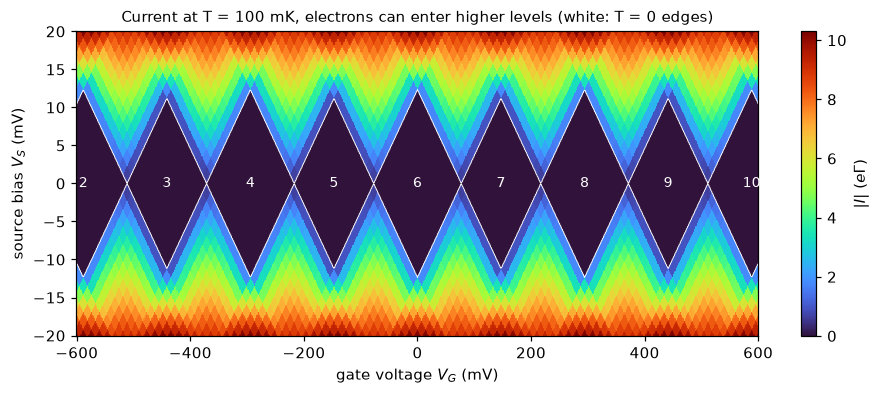

In [9]:
fig, ax = plt.subplots(figsize=(10, 3.6))
im = ax.imshow(np.abs(I_T), extent=[-600.5, 600.5, -20.05, 20.05], origin='lower', aspect='auto',
               cmap='turbo', interpolation='nearest')  # |current| at every point
ax.contour(VG/mV, VS/mV, blockaded_0.astype(float), levels=[0.5], colors='w', linewidths=.6)  # T = 0 diamond edges
for n in range(1, 2*isl_T.p.K - 2):  # write n in the middle of each diamond, as in the T = 0 map
    xc = 0.5*(isl_T.V_peak(n-1)+isl_T.V_peak(n))/mV
    if -600 < xc < 600: ax.text(xc, 0, str(n - n_shift), ha='center', va='center', fontsize=9, color='w')
fig.colorbar(im, ax=ax, label=r'$|I|$ ($e\Gamma$)')
ax.set_xlabel('gate voltage $V_G$ (mV)'); ax.set_ylabel('source bias $V_S$ (mV)'); ax.grid(False)
ax.set_title(f'Current at T = {T_e / mK:.0f} mK, electrons can enter higher levels (white: T = 0 edges)', fontsize=10)
plt.show()

## Differential Conductance

We masure dI/dV_s, this is large where the current steps and is a line parallel to a diamond edge as in the measured maps.

With equal energy spacing the lines are eavenly spaced.

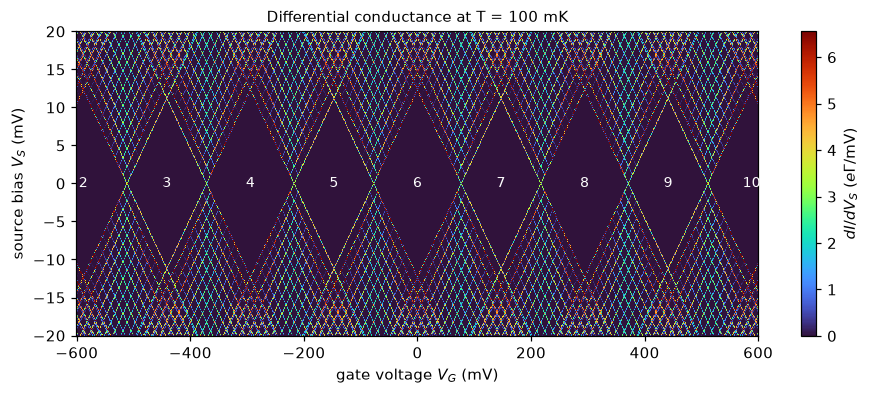

In [10]:
dIdV = np.gradient(I_T, VS / mV, axis=0)  # dI/dV_S in e*Gamma per mV, derivative down each column (the bias axis)
fig, ax = plt.subplots(figsize=(10, 3.6))
im = ax.imshow(dIdV, extent=[-600.5, 600.5, -20.05, 20.05], origin='lower', aspect='auto', cmap='turbo',
               vmin=0, vmax=np.percentile(dIdV, 99), interpolation='nearest')
for n in range(1, 2*isl_T.p.K - 2):
    xc = 0.5*(isl_T.V_peak(n-1)+isl_T.V_peak(n))/mV
    if -600 < xc < 600: ax.text(xc, 0, str(n - n_shift), ha='center', va='center', fontsize=9, color='w')
fig.colorbar(im, ax=ax, label=r'$dI/dV_S$ ($e\Gamma$/mV)')
ax.set_xlabel('gate voltage $V_G$ (mV)'); ax.set_ylabel('source bias $V_S$ (mV)'); ax.grid(False)
ax.set_title(f'Differential conductance at T = {T_e / mK:.0f} mK', fontsize=10)
plt.show()

## One diamond

Now we show the same diamond as before (the n=6 one). The left plot shows the current and the right plot is the dI/dV_s plot

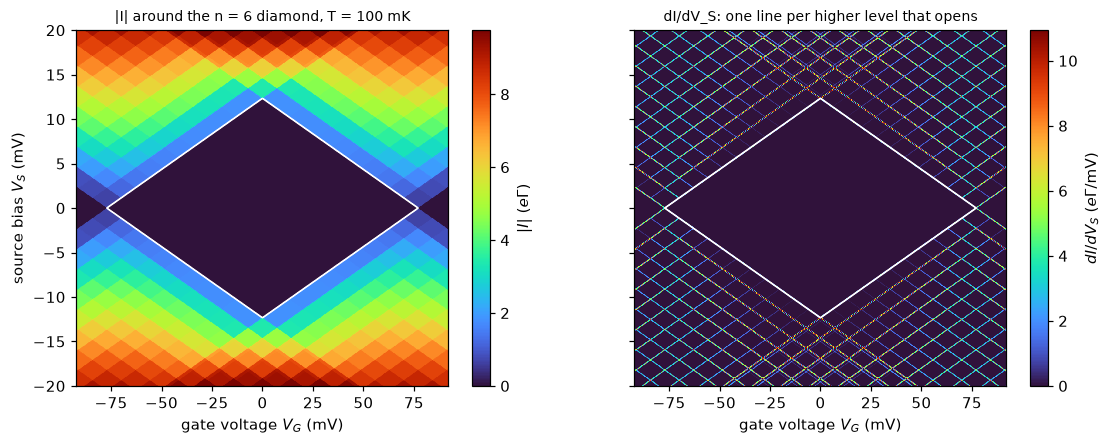

In [12]:
n0 = 6 + n_shift  # the diamond labelled 6, as in the T = 0 plot
vL, vR = isl_T.V_peak(n0-1)/mV, isl_T.V_peak(n0)/mV  # the two Coulomb peaks either side of it (mV)
VGd = np.linspace(vL-15, vR+15, 1500)*mV  # fine grid around this one diamond
VSd = np.arange(-20, 20.001, 0.05)*mV
I_d, _ = current_map(isl_T, VGd, VSd, kT=T_e)
dIdV_d = np.gradient(I_d, VSd / mV, axis=0)  # e*Gamma per mV
_, nmap_d = blockade_map(isl_T, VGd, VSd)  # T = 0 diamond, for the outline

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, data, lab in zip(axs, [np.abs(I_d), dIdV_d], [r'$\vert{}I\vert{}$ ($e\Gamma$)', r'$dI/dV_S$ ($e\Gamma$/mV)']):
    im = ax.imshow(data, extent=[VGd[0]/mV, VGd[-1]/mV, VSd[0]/mV, VSd[-1]/mV], origin='lower', aspect='auto',
                   cmap='turbo', vmin=0, vmax=np.percentile(data, 99.5), interpolation='nearest')
    ax.contour(VGd/mV, VSd/mV, (nmap_d == n0).astype(float), levels=[0.5], colors='w', linewidths=1)  # T = 0 edge
    fig.colorbar(im, ax=ax, label=lab)
    ax.set_xlabel('gate voltage $V_G$ (mV)'); ax.grid(False)

axs[0].set_ylabel('source bias $V_S$ (mV)')
axs[0].set_title(f'|I| around the n = 6 diamond, T = {T_e / mK:.0f} mK', fontsize=9)
axs[1].set_title('dI/dV_S: one line per higher level that opens', fontsize=9)
plt.show()

# What the model still cant do

- The equal level energy spacing means the Coulomb diamonds are still the same size and equally distanced.
- The assumption that the island relaxes into the ground state between tunnelling events may be wrong.
- We use the assumption that $\hbar \Gamma << kT$, they may be comparable.
- The small current inside the diamonds due to stray dopants giving a path for electrons to travel through is not modelled.
- Tunnel rates are not know so the current is in terms of $e\Gamma$
- Defects and stray dopants are the next stage of the project